# EC data analysis with corresponding image data

This notebook plots important elecetrochemical data for CO2ELY and compares it to concurrent and potentially relevant imaging results

TODO:
1. add Bernhard data as reference

In [1]:
#import relevant moduls and define general filepaths
import json
import os
import socket
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    
processing_path = os.path.join(toppath, 'processing')
EC_path = os.path.join(toppath, 'EC_lab_files')
overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))

#go and fetch some tools from the git repo and come back
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)

import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np

deffontsize = mpl.rcParams["font.size"]
print(deffontsize)



10.0


In [2]:
# normalize data versus mormalized charg
def get_principal_data(ECdata):
    dims = np.array([ECdata[i].dims['t'] for i in range(len(ECdata))])
    # print(dims)
    I = np.zeros(dims.sum())
    timestamps = I.copy()
    E = I.copy()
    Re = I.copy()
    Im = I.copy()
    # print(len(dims))

    I[:dims[0]] = ECdata[0]['I'].data
    # timestamps[:dims[0]] = ECdata[0]['t'].data
    timestamps[:dims[0]] = ECdata[0]['timestamp (utc)'].data
    E[:dims[0]] = ECdata[0]['$E_{we}$'].data
    Im[:dims[0]] = ECdata[0]['-Im(Z)'].data
    Re[:dims[0]] = ECdata[0]['Re(Z)'].data

    for i in range(1,len(dims)):
        I[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['I'].data
        timestamps[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['timestamp (utc)'].data
        # timestamps[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['t'].data +ECdata[i-1]['t'].data.max()
        E[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['$E_{we}$'].data
        Im[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['-Im(Z)'].data
        Re[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['Re(Z)'].data
    
    order = timestamps.argsort()
    t0 = timestamps[timestamps>0].min()
    # print(t0)
    I = I[order]
    E = E[order]
    Im = Im[order]
    Re = Re[order]
    timestamps = timestamps[order]
    # print(timestamps[0])
    
#     filter out potential overflow cases
    I = I[E>-5]
    Im = Im[E>-5]
    Re = Re[E>-5]
    timestamps = timestamps[E>-5]
    E = E[E>-5]
    
    time = timestamps - t0
    dt = np.gradient(time)
    Q = np.cumsum(-I*dt)
    return Q, I, E, time, Im, Re, timestamps, t0

In [3]:
#TODO: wrap into sample function, time all in min
def plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50)):

    if unit == 'min':
        tf = 60
    if unit == 's':
        tf = 1


    mpl.rcParams["font.size"] = 24
    fig, ax = plt.subplots(1,3, figsize=(35,12))
    fig.tight_layout(pad=7)
    
    ax2l = ax[0].twinx()

    #plot potential and current in left panel
    # TODO: consider multiple files with timestamps
    # for d in ECdata:
    #     d['$E_{we}$'].plot(ax=ax[0], color='k', label='$E_{we}$')
    #     d['I'].plot(ax=ax2l, color='r', label='I')
    ax[0].plot(time/tf, E,color='k', label='$E_{we}$')
    ax2l.plot(time/tf, I,color='r', label='I')
    ax[0].set_xlim(0,time.max()/tf)
    ax2l.set_xlim(0,time.max()/tf)
    ax[0].set_xlabel('time ['+unit+']')
    ax[0].set_ylabel('$E_{we}$ [V]')
    ax2l.set_ylabel('I [mA]')
    ax[0].legend(loc='lower left')
    ax2l.legend(loc='lower right')
    plt.title(sample)

    #HFR to the middle panel
    # HFR_color_plot_to_axis(ECdata[0], ax[1], fig, markersize=50, yl=(-10,40), unit='s')
    tl = (0,time.max()/tf)
    im = ax[1].scatter(Re, Im, c=time/tf, cmap = cm.viridis, marker='o', s=30, vmin=tl[0], vmax=tl[1])
    ax[1].axhline(0, color='k', linewidth=0.5)
    ax[1].set_xlim(xl[0],xl[1])
    ax[1].set_ylim(yl[0],yl[1])
    ax[1].set_xlabel('Re(Z) [$\Omega$]')
    ax[1].set_ylabel('-Im(Z) [$\Omega$]')

    divider = make_axes_locatable(ax[1])
    cax = divider.append_axes('right', size='5%', pad=0.05)
    fig.colorbar(im, cax=cax, orientation='vertical', label='time ['+unit+']')

    # power vs charge
    ax[2].plot(Q/1000, E*I)
    ax[2].set_xlabel('charge [As]')
    ax[2].set_ylabel('power [mW]')
    ax[2].set_xlim(0,Q.max()/1000)



In [4]:
# global variables and dicts
charge_dict = {}

## Cell 5II
### short description

Potentiostatic operation 3.5V


In [5]:
# load data TODO wrap into function and provided small dossier as dict
sample = '5II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

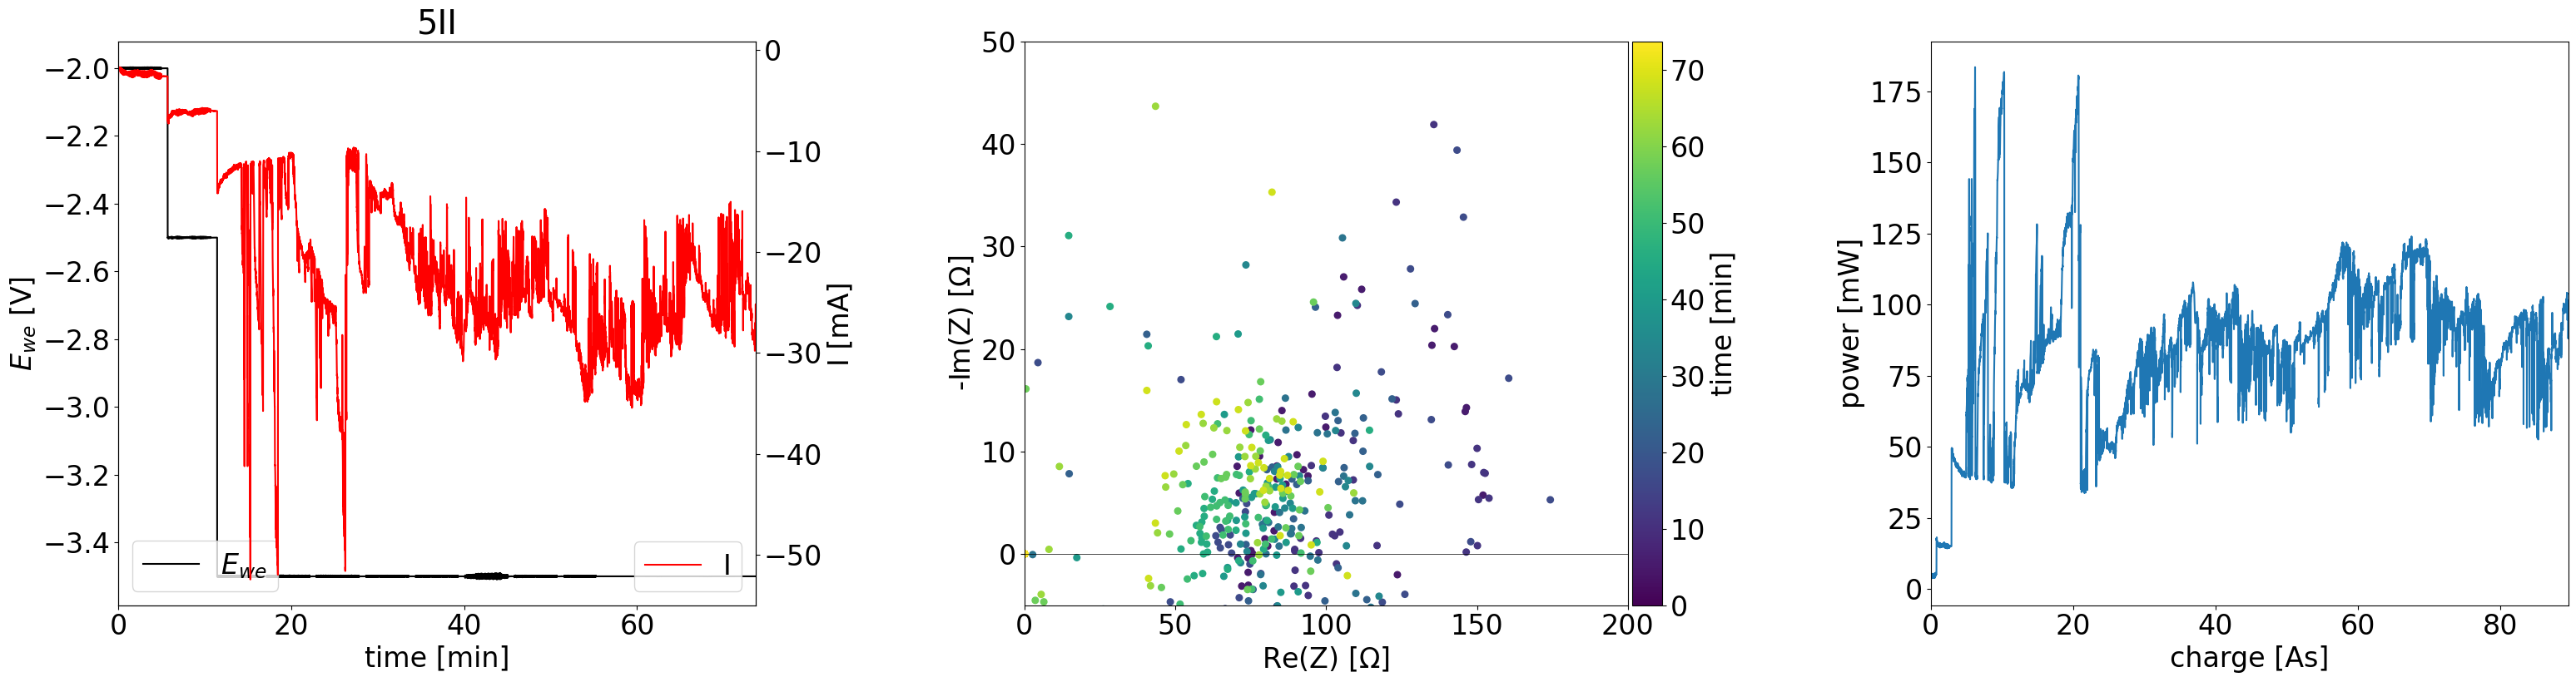

In [6]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 3II
### short description

Potentiostatic operation 3.5V


In [7]:
# load data TODO wrap into function and provided small dossier as dict
sample = '3II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

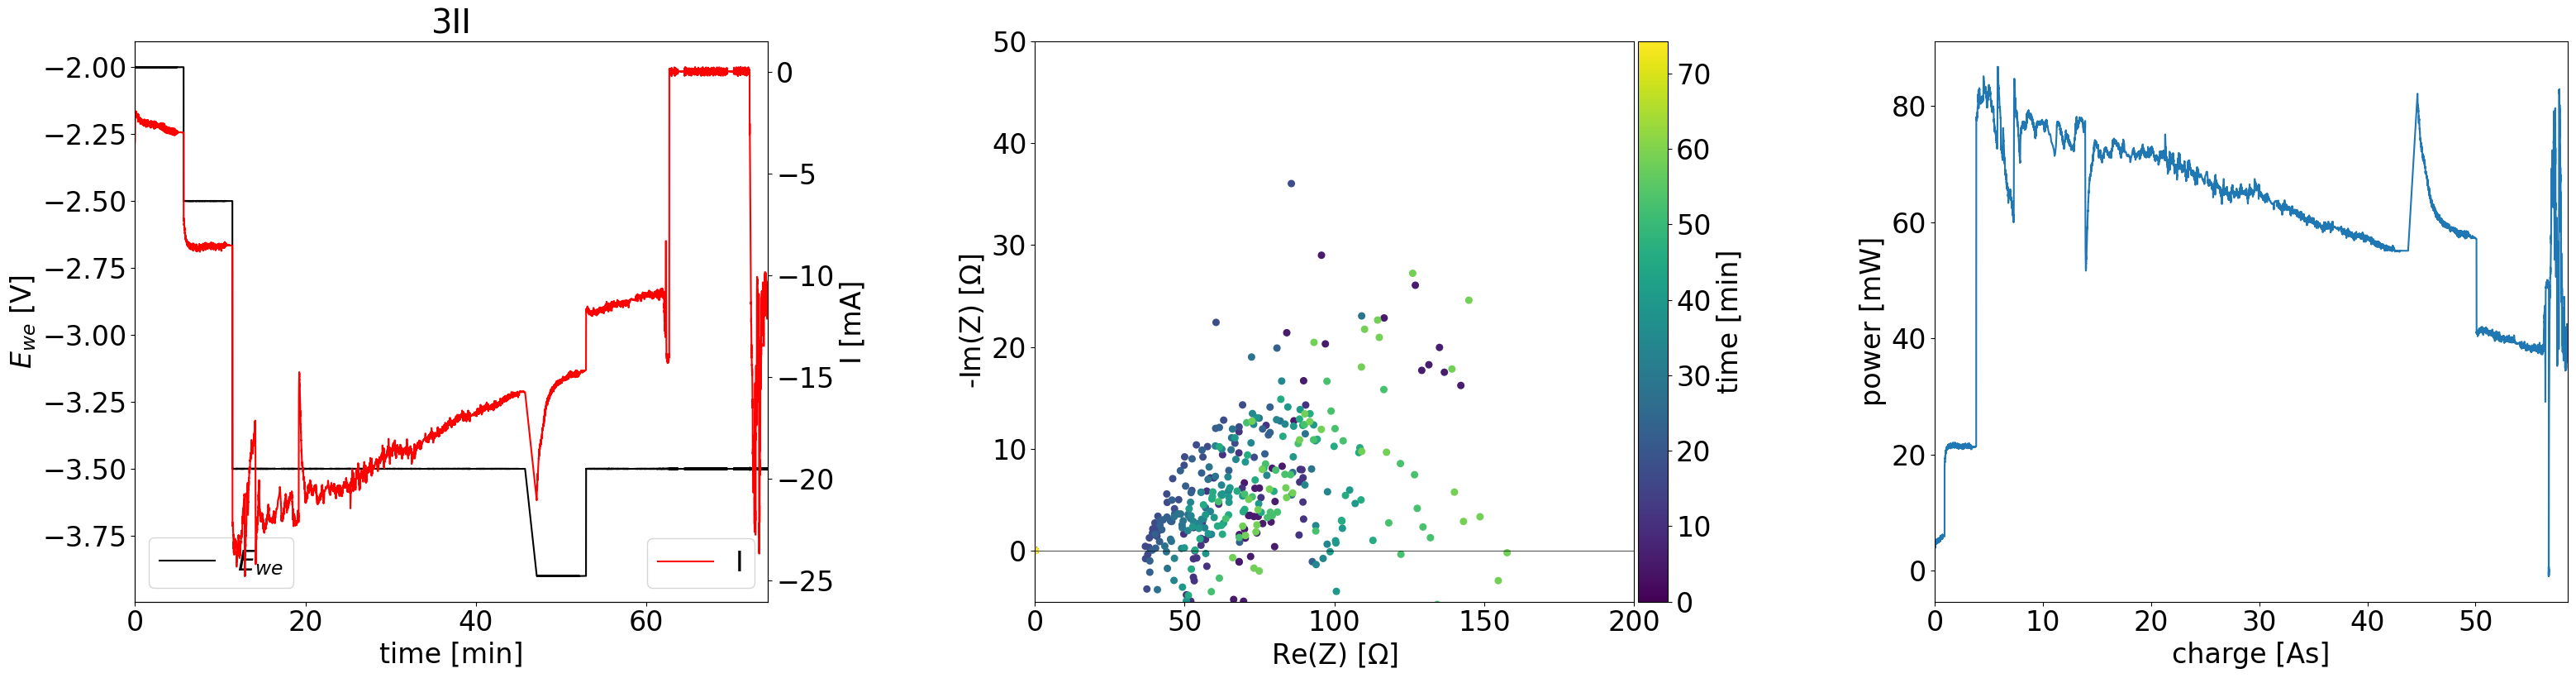

In [8]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 4
### short description

Galvanostatic operation 3mA<br />


In [9]:
# load data TODO wrap into function and provided small dossier as dict
sample = '4'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

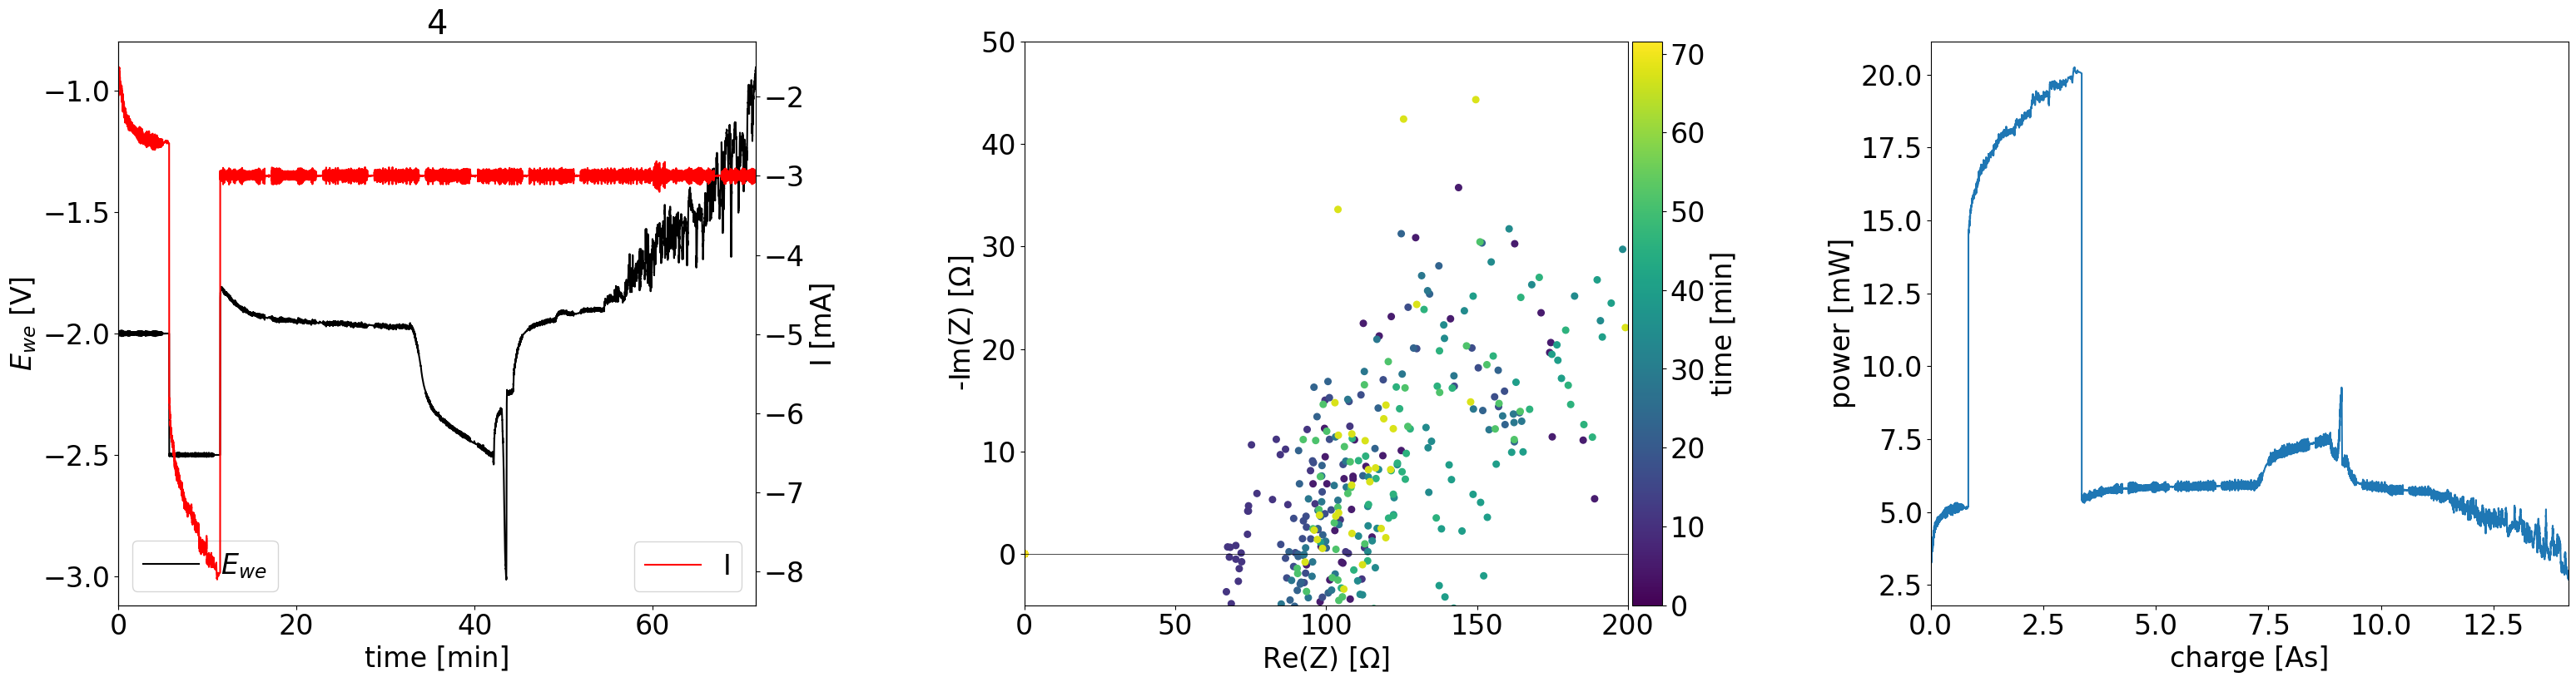

In [10]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 6
### short description

Galvanostatic operation 5mA<br />



In [11]:
# load data TODO wrap into function and provided small dossier as dict
sample = '6'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

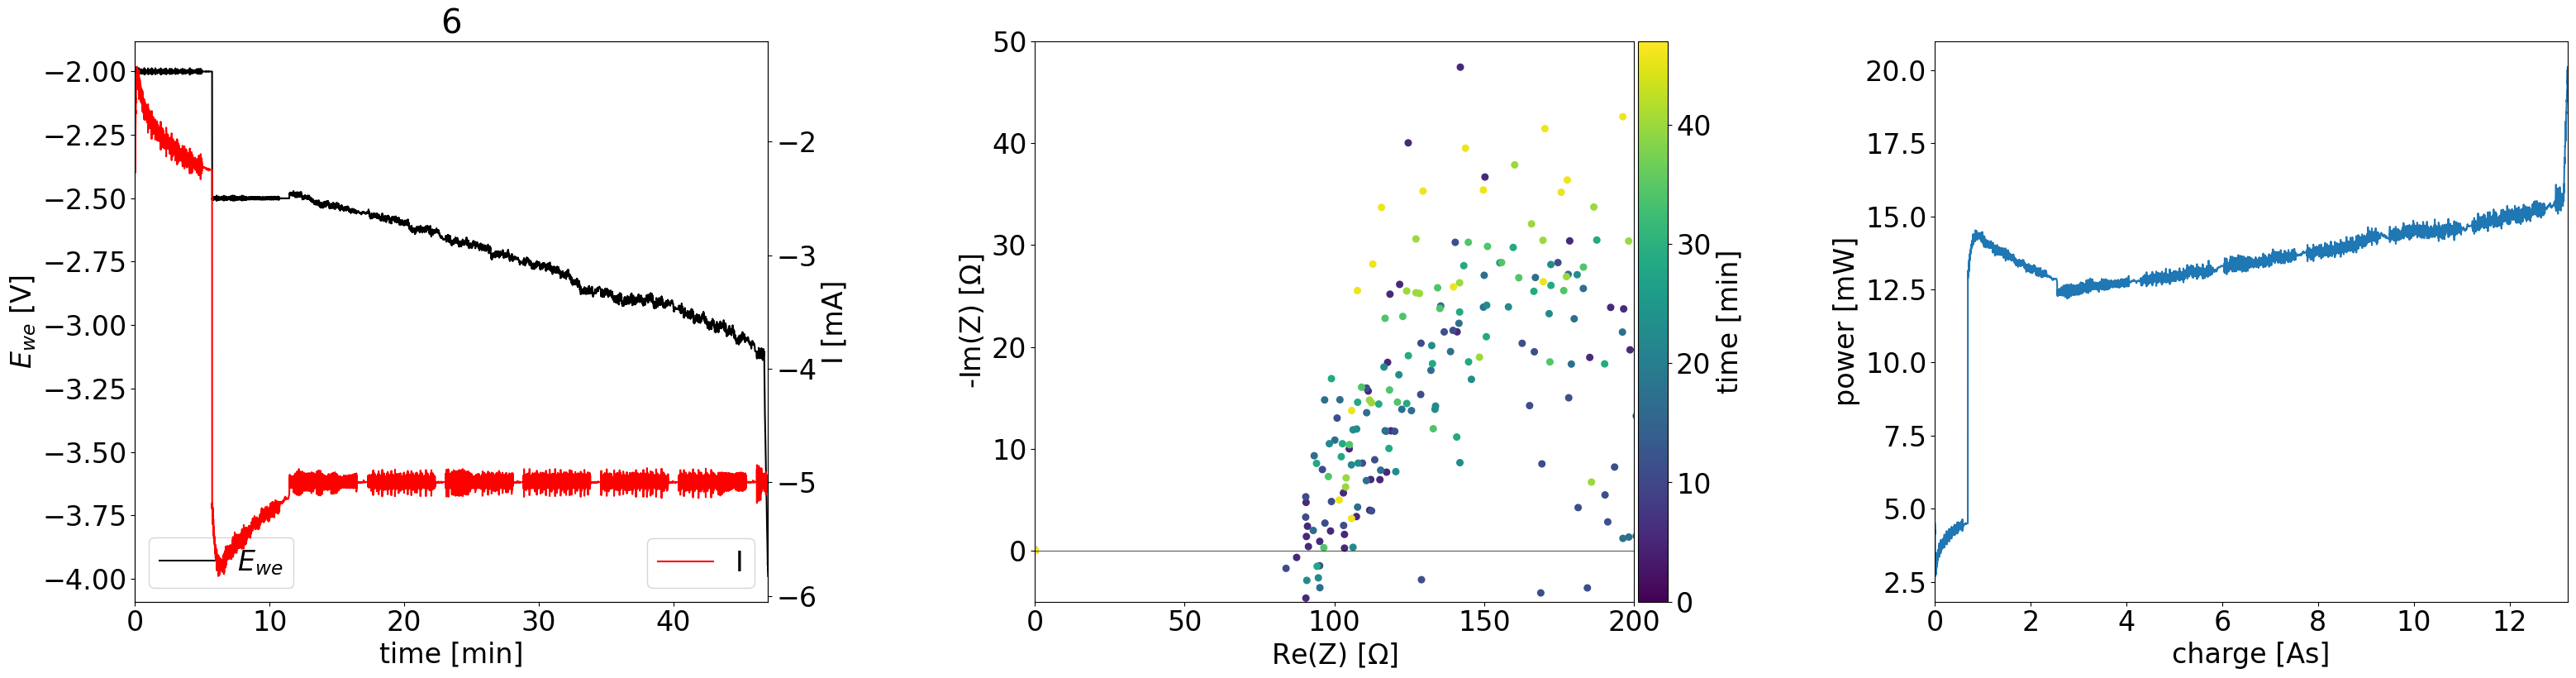

In [12]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 5
### short description

Galvanostatic operation 10mA and 15mA <br />

In [13]:
# load data TODO wrap into function and provided small dossier as dict
sample = '5'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

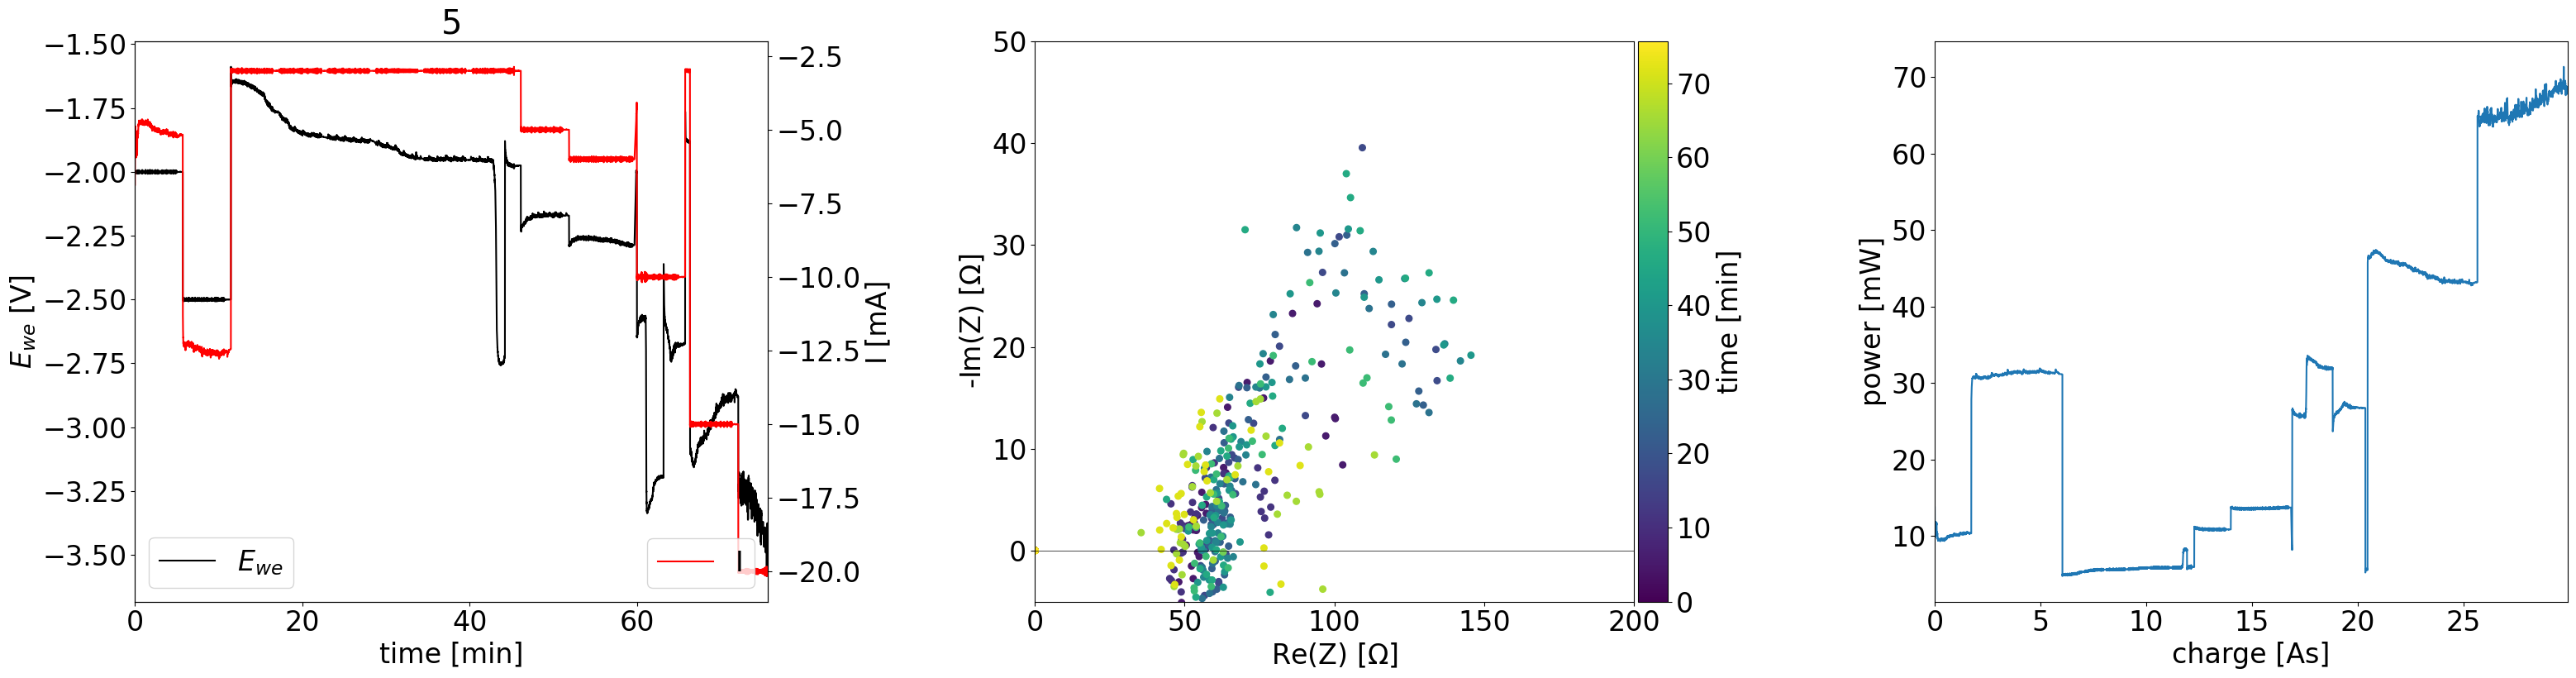

In [14]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 4II
### short description

current rampup <br />
potential safety limit overflow -> filter extreme E values



In [15]:
# load data TODO wrap into function and provided small dossier as dict
sample = '4II'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

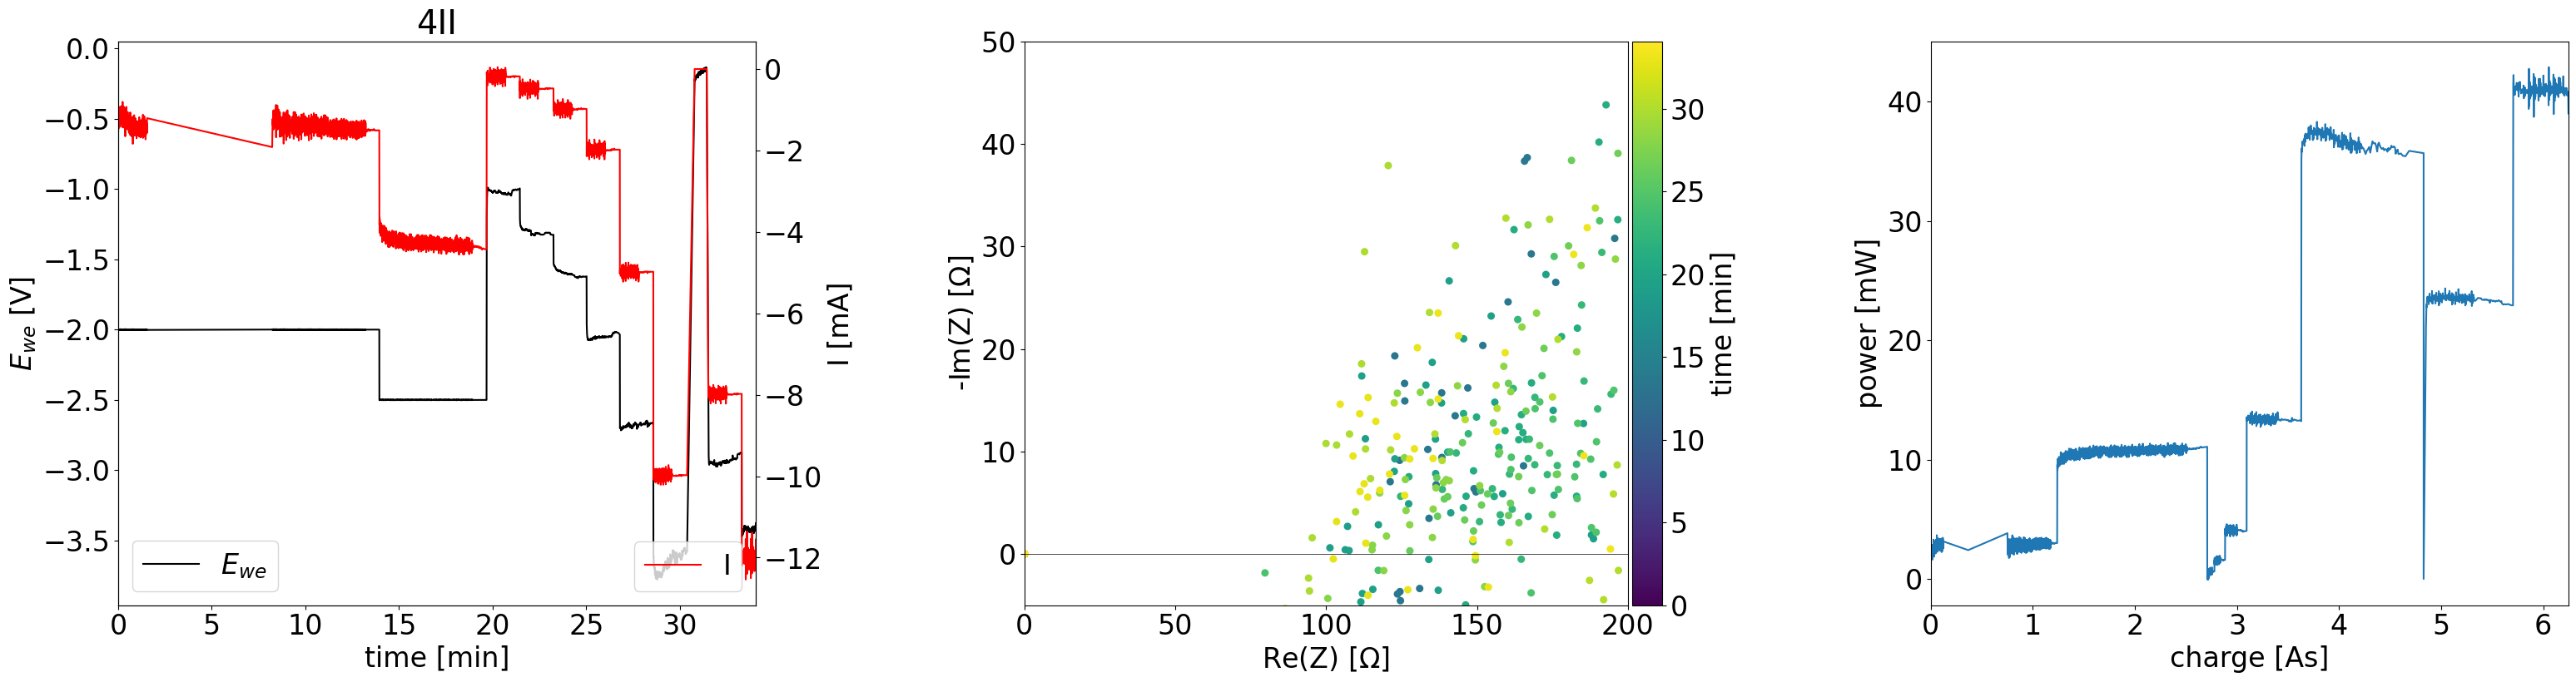

In [16]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 3III
### short description

Galvanostatic 14 mA



In [17]:
# load data TODO wrap into function and provided small dossier as dict
sample = '3III'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

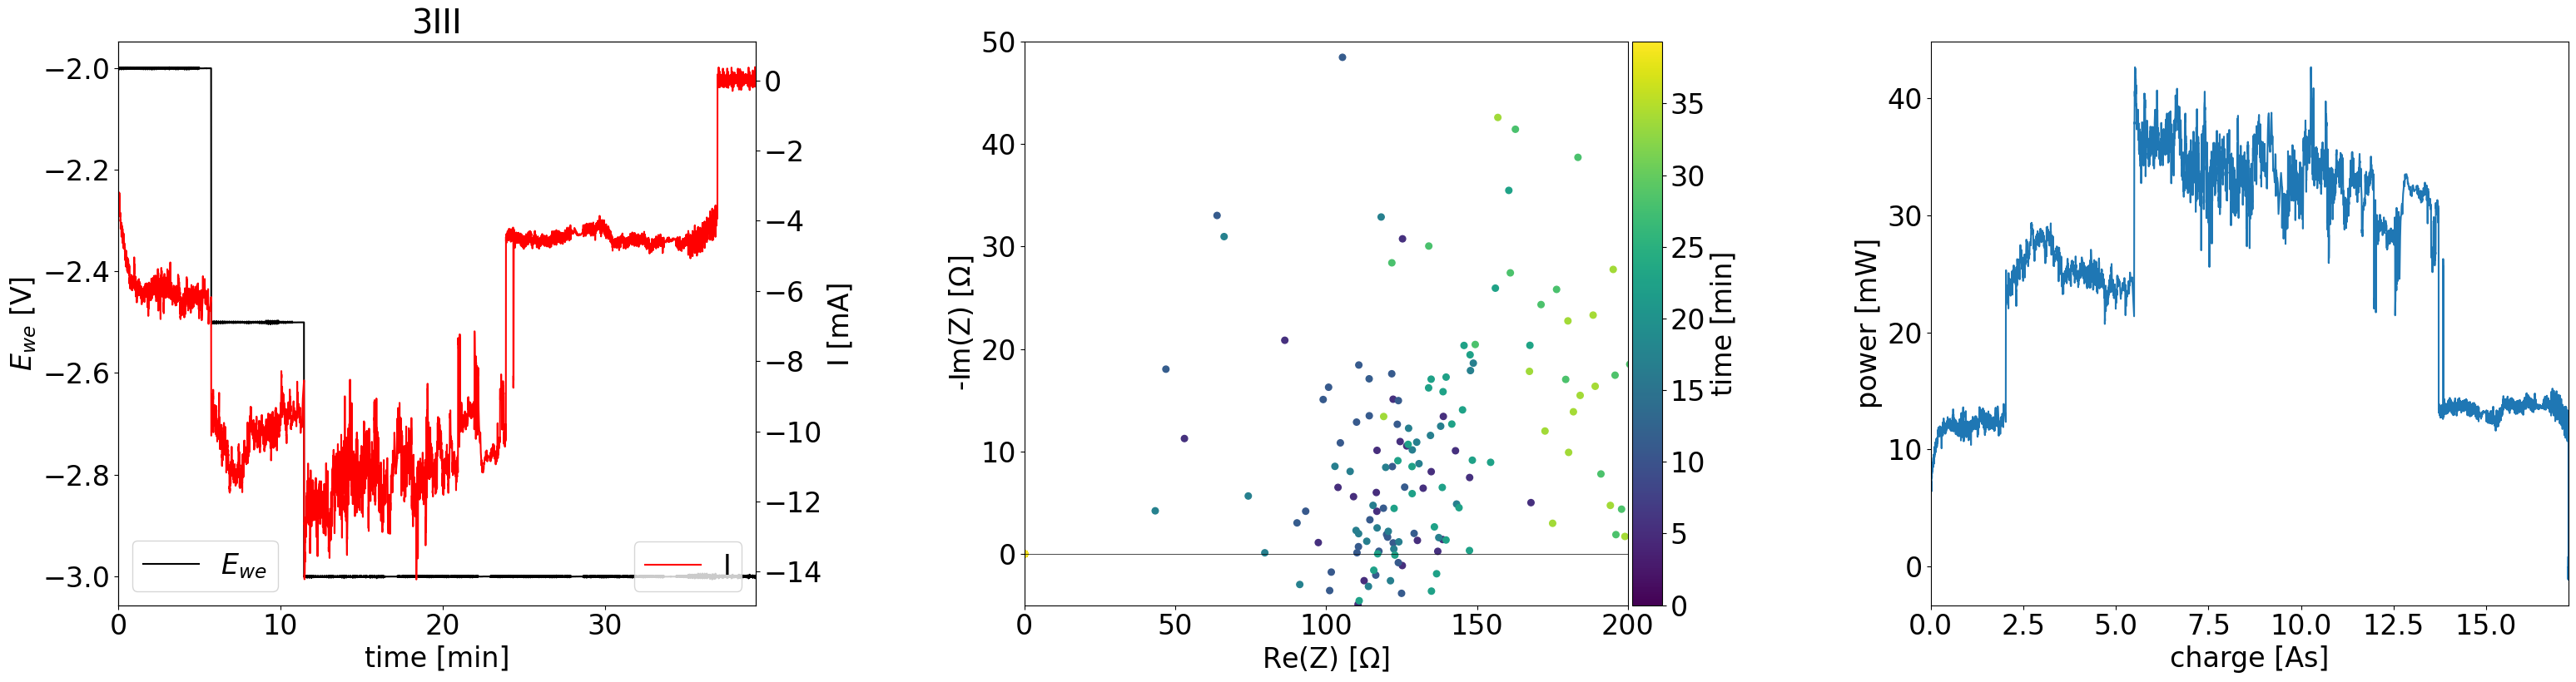

In [18]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))

## Cell 7x
### short description

Galvanostatic 5mA <br />
GDL with punch slits



In [19]:
# load data TODO wrap into function and provided small dossier as dict
sample = '7x'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

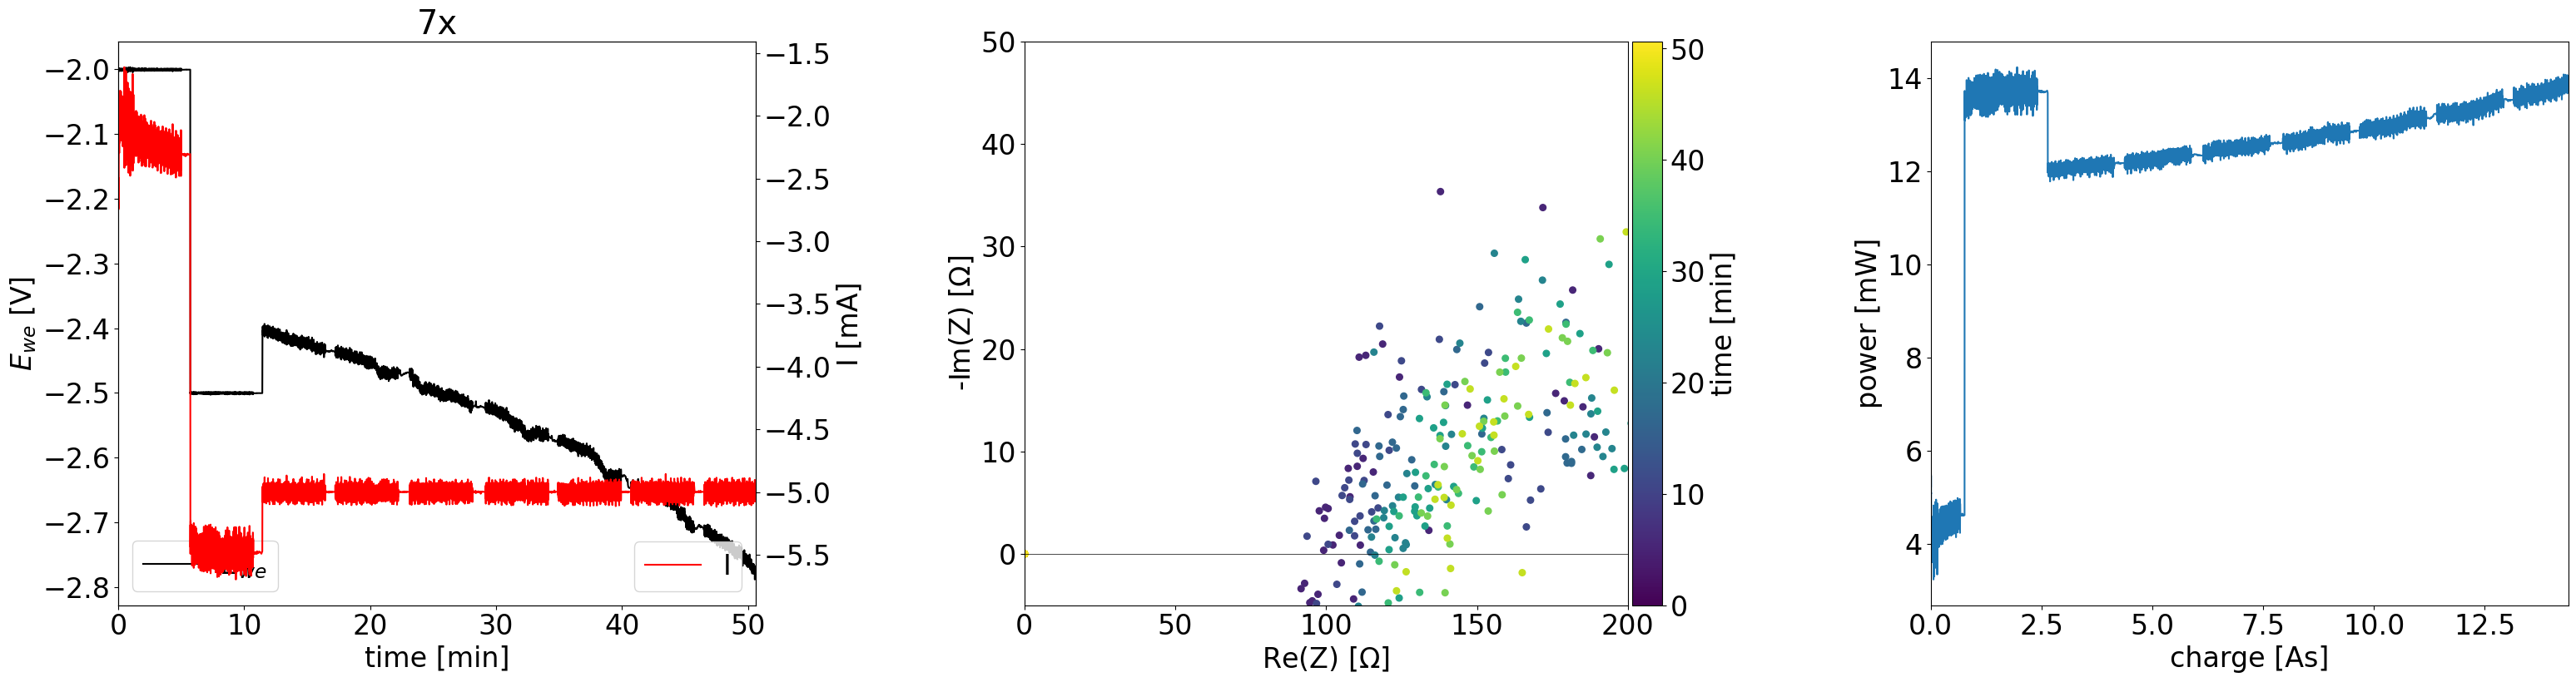

In [20]:
plot_principal_3_plots(Q, I, E, time, Im, Re, sample, unit='min', xl=(0,200), yl=(-5,50))